In [50]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download latest version
path = kagglehub.dataset_download("bordanova/2023-us-civil-flights-delay-meteo-and-aircraft")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ferna\.cache\kagglehub\datasets\bordanova\2023-us-civil-flights-delay-meteo-and-aircraft\versions\9


In [51]:
# Load every CSV into a dict: dfs["orders"], dfs["customers"], ...
dfs = {
    f.removeprefix("olist_").removesuffix("_dataset.csv").removesuffix(".csv"): pd.read_csv(os.path.join(path, f))
    for f in os.listdir(path)
    if f.endswith(".csv")
}
{name: df.shape for name, df in dfs.items()}

{'airports_geolocation': (364, 7),
 'Cancelled_Diverted_2023': (104488, 23),
 'maj us flight - january 2024': (527197, 24),
 'US_flights_2023': (6743404, 24),
 'weather_meteo_by_airport': (132860, 10)}

In [52]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

# Airport columns mix IATA codes and numeric IDs (see findings) -> force str
dfs = {
    "flights": pd.read_csv(os.path.join(path, "US_flights_2023.csv"),
                           dtype={"ORIGIN_AIRPORT": str, "DESTINATION_AIRPORT": str}),
    "cancelled_diverted": pd.read_csv(os.path.join(path, "Cancelled_Diverted_2023.csv")),
    "airports": pd.read_csv(os.path.join(path, "airports_geolocation.csv")),
    "weather": pd.read_csv(os.path.join(path, "weather_meteo_by_airport.csv")),
    "airports": pd.read_csv(os.path.join(path, "airports_geolocation.csv")),
}
flights, cancelled_diverted, airports, weather = dfs["flights"], dfs["cancelled_diverted"], dfs["airports"], dfs["weather"]
# flights["DATE"] = pd.to_datetime(flights[["YEAR", "MONTH", "DAY"]])
for name, df in dfs.items():
    print(f"{name:9s} {df.shape}")

flights   (6743404, 24)
cancelled_diverted (104488, 23)
airports  (364, 7)
weather   (132860, 10)


In [53]:
for table_name in ("flights", "cancelled_diverted", "airports", "weather"):
    print(f"\n{table_name} — {dfs[table_name].shape[0]:,} rows × {dfs[table_name].shape[1]} columns")
    print(dfs[table_name].dtypes.to_string())


flights — 6,743,404 rows × 24 columns
FlightDate              str
Day_Of_Week           int64
Airline                 str
Tail_Number             str
Dep_Airport             str
Dep_CityName            str
DepTime_label           str
Dep_Delay             int64
Dep_Delay_Tag         int64
Dep_Delay_Type          str
Arr_Airport             str
Arr_CityName            str
Arr_Delay             int64
Arr_Delay_Type          str
Flight_Duration       int64
Distance_type           str
Delay_Carrier         int64
Delay_Weather         int64
Delay_NAS             int64
Delay_Security        int64
Delay_LastAircraft    int64
Manufacturer            str
Model                   str
Aicraft_age           int64

cancelled_diverted — 104,488 rows × 23 columns
FlightDate                str
Day_Of_Week             int64
Airline                   str
Tail_Number               str
Cancelled             float64
Diverted              float64
Dep_Airport               str
Dep_CityName              str
D

## Stage 2: Grain

**Target grain of the modeling table: 1 row per scheduled flight (`flight_id`, a surrogate key).**

| Table | Grain | Notes |
|---|---|---|
| `flights` | 1 row per *completed* flight (not cancelled, not diverted) | No flight number, so there is no natural key. The loose key (date, airline, tail, route, daypart) is not unique. |
| `cancelled_diverted` | 1 row per cancelled **or** diverted flight | Same schema as `flights` plus `Cancelled`/`Diverted`, minus the aircraft columns. The complement of `flights`, so it gets **stacked** (union), not merged. |
| `weather` | 1 row per (`airport_id`, `time` = day) | Daily aggregates. Joined twice: to the departure airport and to the arrival airport. |
| `airports` | 1 row per `IATA_CODE` | Not joined yet (only needed for geo features). |

In [54]:
FLIGHT_KEY = ["FlightDate", "Airline", "Tail_Number", "Dep_Airport", "Arr_Airport", "DepTime_label"]
findings = []  # (table, issue, rows, decision)

def checked_merge(left, right, on, validate="many_to_one", name=""):
    """Left join that asserts no row explosion and logs counts."""
    out = left.merge(right, on=on, how="left", validate=validate, indicator=True)
    unmatched = (out.pop("_merge") == "left_only").sum()
    print(f"{name}: {len(left):,} -> {len(out):,} rows | unmatched: {unmatched:,}")
    assert len(out) == len(left)
    return out, unmatched

# Grain checks
assert not weather.duplicated(["airport_id", "time"]).any()
assert airports["IATA_CODE"].is_unique
assert ((cancelled_diverted["Cancelled"] + cancelled_diverted["Diverted"]) == 1).all()

for name, df in [("flights", flights), ("cancelled_diverted", cancelled_diverted)]:
    n_full, n_key = df.duplicated().sum(), df.duplicated(FLIGHT_KEY).sum()
    print(f"{name}: full-row dups {n_full:,} | dups on loose key {n_key:,}")
    findings.append((name, "Identical full rows (no flight number to tell them apart)", n_full,
                     "Kept: could be distinct flights by the same tail on the same route/daypart"))

overlap = flights[FLIGHT_KEY].drop_duplicates().merge(cancelled_diverted[FLIGHT_KEY].drop_duplicates(), on=FLIGHT_KEY)
print(f"loose-key overlap flights ∩ cancelled_diverted: {len(overlap):,}")
findings.append(("flights+cancelled_diverted", "Loose key appears in both tables", len(overlap),
                 "Kept: the loose key isn't unique even within flights, so this is not evidence of double counting"))

flights: full-row dups 31 | dups on loose key 24,168
cancelled_diverted: full-row dups 945 | dups on loose key 960
loose-key overlap flights ∩ cancelled_diverted: 747


## Stage 3: Joins

### 3a. Stack `flights` + `cancelled_diverted`
Before stacking, the two tables need to be made consistent:
- **Structural zeros become NaN.** In `cancelled_diverted`, arrival delay, duration and the five delay causes are 0-filled, but they were never observed. Departure delay is also unobserved for cancelled flights. Diverted flights keep their real `Dep_Delay`.
- **Labels.** The two tables use different label sets. The delay bands are recomputed from the numbers (thresholds ≤15 / 16–60 / >60, checked against both label sets), and `Distance_type` drops its misleading mileage suffix (e.g. "Short Haul >1500Mi").
- **Aircraft.** `cancelled_diverted` has no aircraft columns. They're recovered from `flights` through `Tail_Number`, which maps to exactly one aircraft.

In [55]:
AIRCRAFT_COLS = ["Manufacturer", "Model", "Aicraft_age"]
UNOBSERVED_IF_NOT_COMPLETED = ["Arr_Delay", "Flight_Duration", "Delay_Carrier", "Delay_Weather",
                               "Delay_NAS", "Delay_Security", "Delay_LastAircraft"]
BANDS, BAND_LABELS = [-np.inf, 15, 60, np.inf], ["<=15", "16-60", ">60"]
OLD_BAND_MAP = {  # original label -> band (checked below against the numbers)
    "Low <5min": "<=15", "Medium >15min": "16-60", "Hight >60min": ">60",
    "No Departure Delay": "<=15", "Low Departure Delay": "16-60", "Hight Departure Delay": ">60",
}

def delay_band(s):
    return pd.cut(s, BANDS, labels=BAND_LABELS).astype("str").where(s.notna())

fl = flights.assign(Cancelled=0, Diverted=0, src_table="flights")
cd = cancelled_diverted.assign(src_table="cancelled_diverted")
cd[["Cancelled", "Diverted"]] = cd[["Cancelled", "Diverted"]].astype(int)

# The original labels must agree with the numeric thresholds before they're replaced
assert (fl["Dep_Delay_Type"].map(OLD_BAND_MAP) == delay_band(fl["Dep_Delay"])).all()
assert (fl["Arr_Delay_Type"].map(OLD_BAND_MAP) == delay_band(fl["Arr_Delay"])).all()
assert (cd["Dep_Delay_Type"].map(OLD_BAND_MAP) == delay_band(cd["Dep_Delay"])).all()
assert (fl["Dep_Delay_Tag"] == fl["Dep_Delay"].gt(0).astype(int)).all()

# Structural zeros -> NaN
canc = cd["Cancelled"].eq(1)
n_canc_dep = (canc & cd["Dep_Delay"].ne(0)).sum()
cd.loc[canc, "Dep_Delay"] = np.nan
cd[UNOBSERVED_IF_NOT_COMPLETED] = np.nan
findings += [
    ("cancelled_diverted", "Arr_Delay/Flight_Duration/delay causes 0-filled, never observed", len(cd), "Set to NaN"),
    ("cancelled_diverted", "Dep_Delay on cancelled flights (0-filled; a few are nonzero, e.g. delayed then cancelled)",
     canc.sum(), f"Set to NaN ({n_canc_dep:,} had a nonzero value)"),
]

# Aircraft attributes from flights (tail -> aircraft is 1:1)
aircraft = flights[["Tail_Number", *AIRCRAFT_COLS]].drop_duplicates()
assert aircraft["Tail_Number"].is_unique
cd, n_no_tail = checked_merge(cd, aircraft, on="Tail_Number", name="cancelled_diverted + aircraft")
findings.append(("cancelled_diverted", "Tail_Number never seen in flights -> no aircraft attributes", n_no_tail, "Kept with NaN"))

# Stack, then recompute the harmonized labels from the numbers
assert set(fl.columns) == set(cd.columns)
df = pd.concat([fl, cd[fl.columns]], ignore_index=True)
assert len(df) == len(flights) + len(cancelled_diverted)
df["Dep_Delay_Type"] = delay_band(df["Dep_Delay"])
df["Arr_Delay_Type"] = delay_band(df["Arr_Delay"])
df["Dep_Delay_Tag"] = df["Dep_Delay"].gt(0).astype("Int8").where(df["Dep_Delay"].notna())
df["Distance_type"] = df["Distance_type"].str.extract(r"^(\w+ Haul)", expand=False)
assert df["Distance_type"].notna().all()
findings.append(("both", "Label sets differ between tables; '<5min' and '>1500Mi' labels contradict the data",
                 len(df), "Delay bands recomputed from minutes (<=15/16-60/>60); mileage suffix dropped from Distance_type"))

# Dates, calendar consistency, surrogate key (deterministic order)
df["FlightDate"] = pd.to_datetime(df["FlightDate"])
assert (df["Day_Of_Week"] == df["FlightDate"].dt.dayofweek + 1).all()  # 1 = Monday
df = df.sort_values(["FlightDate", "Dep_Airport", "Airline", "Tail_Number", "src_table"], kind="stable").reset_index(drop=True)
df.insert(0, "flight_id", np.arange(len(df)))
del fl, cd
print(f"stacked: {len(df):,} rows | cancelled {df['Cancelled'].sum():,} | diverted {df['Diverted'].sum():,}")

cancelled_diverted + aircraft: 104,488 -> 104,488 rows | unmatched: 15,487
stacked: 6,847,892 rows | cancelled 87,936 | diverted 16,552


### 3b. Weather at the departure and arrival airports
Weather is joined on (airport, `FlightDate`) twice, with the prefixes `wx_dep_` and `wx_arr_`.

The dataset has no arrival date, so arrival-airport weather uses the **departure** date (red-eyes are off by one day). All weather columns are **daily aggregates**: a value like `prcp` for a day is only fully known at the end of that day (`available_at = day_end`). For a model that predicts before departure, they stand in for a forecast and count as a leakage risk. Stage 4 records this in the data dictionary.

In [56]:
WX_COLS = ["tavg", "tmin", "tmax", "prcp", "snow", "wdir", "wspd", "pres"]
wx = weather.assign(FlightDate=pd.to_datetime(weather["time"])).drop(columns="time")

for side, airport_col in [("dep", "Dep_Airport"), ("arr", "Arr_Airport")]:
    w = wx.rename(columns={"airport_id": airport_col, **{c: f"wx_{side}_{c}" for c in WX_COLS}})
    df, n_unmatched = checked_merge(df, w, on=[airport_col, "FlightDate"], name=f"+ weather ({side})")
    assert n_unmatched == 0

# Low-cardinality strings -> category (memory)
for c in ["Airline", "Tail_Number", "Dep_Airport", "Dep_CityName", "DepTime_label", "Dep_Delay_Type",
          "Arr_Airport", "Arr_CityName", "Arr_Delay_Type", "Distance_type", "Manufacturer", "Model", "src_table"]:
    df[c] = df[c].astype("category")

assert df["flight_id"].is_unique and len(df) == len(flights) + len(cancelled_diverted)
print(f"joined: {df.shape[0]:,} rows × {df.shape[1]} cols | {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

+ weather (dep): 6,847,892 -> 6,847,892 rows | unmatched: 0
+ weather (arr): 6,847,892 -> 6,847,892 rows | unmatched: 0
joined: 6,847,892 rows × 44 cols | 1.78 GB


## Target: `delayed_flight`

`delayed_flight = 1` if the flight left **15 minutes or more** after its scheduled departure (`Dep_Delay >= 15`, the official US DOT on-time definition), else 0. `Dep_Delay_Tag` (any delay > 0 min) is not used as a target.
- Cancelled flights never departed, so their target is NaN and they are left out of the target rows. Diverted flights did depart and keep their tag.
- **Prediction time:** before departure. `Dep_Delay`, `Dep_Delay_Tag`, `Dep_Delay_Type`, `Arr_*`, `Flight_Duration`, the `Delay_*` causes, `Cancelled` and `Diverted` are all only known after departure. They can never be features of this target.
- **To check:** `DepTime_label` should be based on the *scheduled* departure time. Cancelled flights also have one, which suggests it is, but if it were based on the actual departure time it would leak.

In [57]:
df["delayed_flight"] = df["Dep_Delay"].ge(15).astype("Int8").where(df["Dep_Delay"].notna())
tgt = df.loc[df["delayed_flight"].notna()].copy()
tgt["delayed_flight"] = tgt["delayed_flight"].astype(int)
tgt["month"] = tgt["FlightDate"].dt.month
base_rate = tgt["delayed_flight"].mean()
print(f"target rows: {len(tgt):,} (excluded {df['delayed_flight'].isna().sum():,} cancelled flights, NaN target)")
print(f"base rate (Dep_Delay >= 15 min): {base_rate:.1%}")

target rows: 6,759,956 (excluded 87,936 cancelled flights, NaN target)
base rate (Dep_Delay >= 15 min): 20.5%


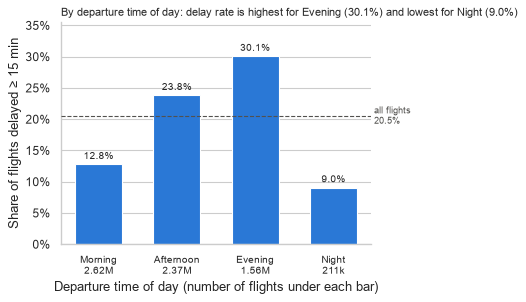

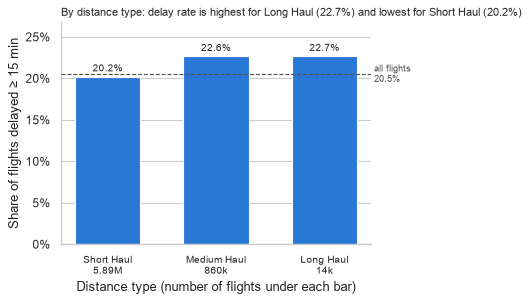

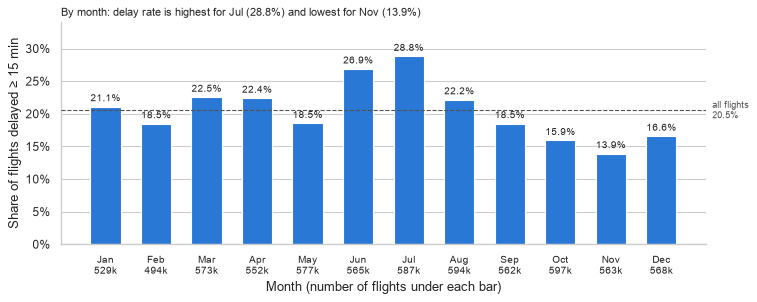

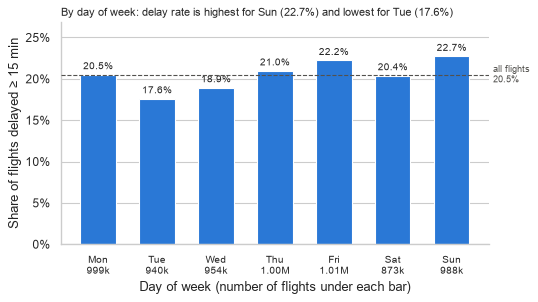

In [58]:
SERIES, REF = "#2a78d6", "#52514e"
DIMENSIONS = [  # (column, display name, category order, tick labels)
    ("DepTime_label", "departure time of day", ["Morning", "Afternoon", "Evening", "Night"], None),
    ("Distance_type", "distance type", ["Short Haul", "Medium Haul", "Long Haul"], None),
    ("month", "month", list(range(1, 13)), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]),
    ("Day_Of_Week", "day of week", list(range(1, 8)), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]),
]

def fmt_count(n):
    return f"{n / 1e6:.2f}M" if n >= 1e6 else f"{n / 1e3:.0f}k"

def plot_delay_rate(col, name, order, labels=None):
    g = tgt.groupby(col, observed=True)["delayed_flight"].agg(rate="mean", n="size").reindex(order)
    labels = labels or [str(o) for o in order]
    lab = dict(zip(order, labels))
    hi, lo = g["rate"].idxmax(), g["rate"].idxmin()

    fig, ax = plt.subplots(figsize=(max(5, 0.7 * len(g) + 2), 3.6))
    x = np.arange(len(g))
    bars = ax.bar(x, g["rate"], width=0.6, color=SERIES, zorder=2)
    ax.bar_label(bars, labels=[f"{r:.1%}" for r in g["rate"]], padding=3, fontsize=9)
    ax.axhline(base_rate, color=REF, ls="--", lw=1, zorder=3)
    ax.text(1.01, base_rate, f"all flights\n{base_rate:.1%}", transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=8, color=REF)
    ax.set_xticks(x, [f"{l}\n{fmt_count(n)}" for l, n in zip(labels, g["n"])], fontsize=9)
    ax.set_ylim(0, g["rate"].max() * 1.18)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.set_ylabel("Share of flights delayed ≥ 15 min")
    ax.set_xlabel(f"{name.capitalize()} (number of flights under each bar)")
    ax.set_title(f"By {name}: delay rate is highest for {lab[hi]} ({g.loc[hi, 'rate']:.1%}) "
                 f"and lowest for {lab[lo]} ({g.loc[lo, 'rate']:.1%})", fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)
    plt.show()
    return g.assign(label=labels)

rate_tables = {col: plot_delay_rate(col, name, order, labels) for col, name, order, labels in DIMENSIONS}

## Weather vs. `delayed_flight`

Each weather variable is cut into bins. The delay rate is plotted per bin twice: once using the **origin** airport's weather (`wx_dep_*`) and once using the **destination** airport's (`wx_arr_*`). Bins with fewer than 1,000 flights are left off the line.

Read these with care:
- **Units:** `prcp` is daily precipitation (mm), `snow` is **snow depth on the ground** (mm, not snowfall), `wspd` is the daily mean wind speed (km/h), `tavg` is the daily mean temperature (°C), and `pres` is sea-level pressure (hPa). `wdir` is skipped: wind direction means nothing without the runway layout.
- **Daily values:** these are daily aggregates known at the end of the day (`available_at = day_end`). For a pre-departure model they stand in for a forecast.
- **Confounding:** weather moves with season, and so do delays (Jun–Jul peak). The last plot compares rainy and dry days *within* each month to separate the two.

tmin <= tavg <= tmax violated: 358 airport-days | tmin < -45 °C: 1


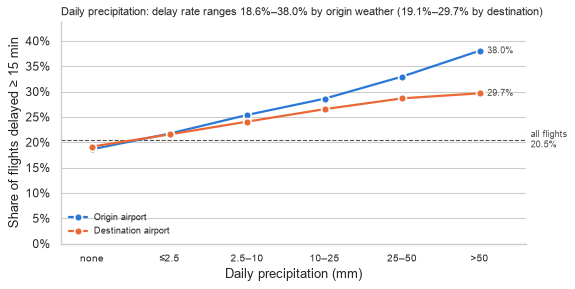

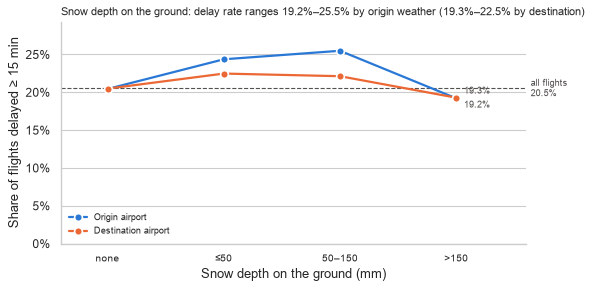

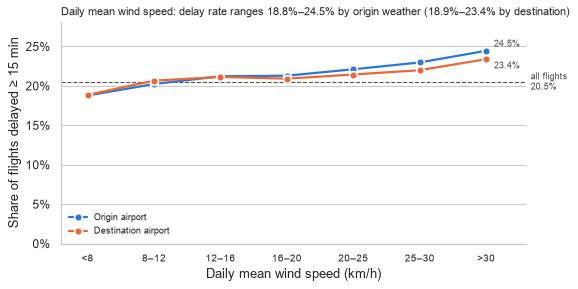

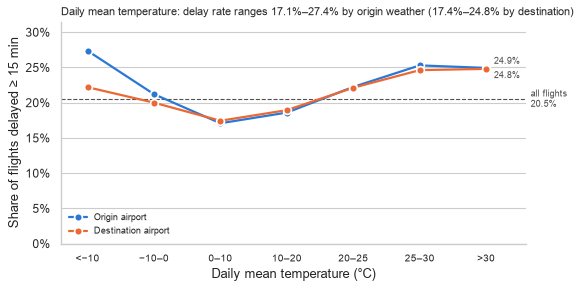

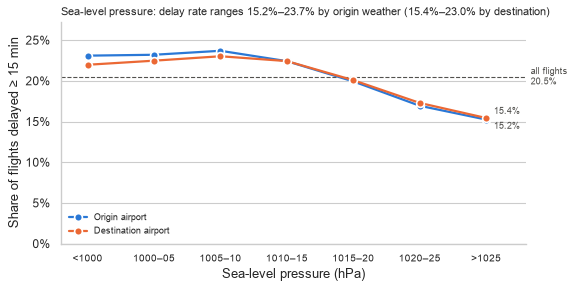

In [59]:
# Weather sanity checks (raw weather table)
t_order_bad = ~((weather["tmin"] <= weather["tavg"]) & (weather["tavg"] <= weather["tmax"]))
n_cold = (weather["tmin"] < -45).sum()
print(f"tmin <= tavg <= tmax violated: {t_order_bad.sum():,} airport-days | tmin < -45 °C: {n_cold:,}")
findings += [
    ("weather", "tmin <= tavg <= tmax violated", t_order_bad.sum(), "Kept; only tavg is used in the plots"),
    ("weather", "tmin below -45 °C (min -76 °C, implausible for US airports)", n_cold, "Kept; flag before using tmin as a feature"),
]

WX_BINS = {  # var: (bin edges, labels, axis name)
    "prcp": ([-np.inf, 0, 2.5, 10, 25, 50, np.inf], ["none", "≤2.5", "2.5–10", "10–25", "25–50", ">50"], "Daily precipitation (mm)"),
    "snow": ([-np.inf, 0, 50, 150, np.inf], ["none", "≤50", "50–150", ">150"], "Snow depth on the ground (mm)"),
    "wspd": ([-np.inf, 8, 12, 16, 20, 25, 30, np.inf], ["<8", "8–12", "12–16", "16–20", "20–25", "25–30", ">30"], "Daily mean wind speed (km/h)"),
    "tavg": ([-np.inf, -10, 0, 10, 20, 25, 30, np.inf], ["<−10", "−10–0", "0–10", "10–20", "20–25", "25–30", ">30"], "Daily mean temperature (°C)"),
    "pres": ([-np.inf, 1000, 1005, 1010, 1015, 1020, 1025, np.inf], ["<1000", "1000–05", "1005–10", "1010–15", "1015–20", "1020–25", ">1025"], "Sea-level pressure (hPa)"),
}
SIDES = [("dep", "Origin airport", "#2a78d6"), ("arr", "Destination airport", "#eb6834")]
TEXT, MIN_FLIGHTS = "#52514e", 1_000

def wx_rate_table(var):
    edges, labels, _ = WX_BINS[var]
    parts = {}
    for side, *_ in SIDES:
        b = pd.cut(tgt[f"wx_{side}_{var}"], edges, labels=labels)
        parts[side] = tgt.groupby(b, observed=False)["delayed_flight"].agg(rate="mean", n="size")
    t = pd.concat(parts, axis=1)
    for side, *_ in SIDES:
        t[(side, "rate")] = t[(side, "rate")].where(t[(side, "n")] >= MIN_FLIGHTS)
    return t

def plot_wx(var):
    _, labels, name = WX_BINS[var]
    t = wx_rate_table(var)
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    x = np.arange(len(labels))
    ends = []
    for side, side_name, color in SIDES:
        r = t[(side, "rate")].to_numpy()
        ax.plot(x, r, color=color, lw=2, marker="o", ms=7, mec="white", mew=1.5, label=side_name, zorder=3)
        i = np.flatnonzero(~np.isnan(r))[-1]
        ends.append((x[i], r[i]))
    # End labels: push apart vertically when the two end values are close
    close = abs(ends[0][1] - ends[1][1]) < 0.015
    for k, (xi, ri) in enumerate(ends):
        dy = (6 if ri >= ends[1 - k][1] and (k == 0 or ri != ends[0][1]) else -6) if close else 0
        ax.annotate(f"{ri:.1%}", (xi, ri), xytext=(7, dy), textcoords="offset points",
                    va="center", fontsize=8, color=TEXT)
    ax.axhline(base_rate, color=TEXT, ls="--", lw=1, zorder=2)
    ax.text(1.01, base_rate, f"all flights\n{base_rate:.1%}", transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=8, color=TEXT)
    ax.set_xticks(x, labels, fontsize=9)
    ax.set_xlim(-0.4, len(x) - 0.4)
    ax.set_ylim(0, np.nanmax(t.xs("rate", axis=1, level=1).to_numpy()) * 1.15)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.set_ylabel("Share of flights delayed ≥ 15 min")
    ax.set_xlabel(name)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="lower left", fontsize=8, frameon=False)
    o, d = t[("dep", "rate")], t[("arr", "rate")]
    ax.set_title(f"{name.split(' (')[0]}: delay rate ranges {o.min():.1%}–{o.max():.1%} by origin weather "
                 f"({d.min():.1%}–{d.max():.1%} by destination)", fontsize=10, loc="left")
    sns.despine(ax=ax)
    plt.show()
    return t

wx_tables = {var: plot_wx(var) for var in WX_BINS}

In [60]:
# Flights per bin behind each line
pd.concat({var: pd.DataFrame({
    "origin_rate_%": (t[("dep", "rate")] * 100).round(1), "origin_n": t[("dep", "n")],
    "dest_rate_%": (t[("arr", "rate")] * 100).round(1), "dest_n": t[("arr", "n")],
}) for var, t in wx_tables.items()})

origin_rate_%  origin_n  dest_rate_%   dest_n
prcp none              18.6   4759614         19.1  4757925
     ≤2.5              21.7    885412         21.5   885168
     2.5–10            25.4    602818         24.1   603268
     10–25             28.6    353320         26.5   354201
     25–50             32.9    126417         28.7   126872
     >50               38.0     32375         29.7    32522
snow none              20.4   6598027         20.5  6597950
     ≤50               24.4     69384         22.5    69380
     50–150            25.5     52704         22.1    52775
     >150              19.2     39841         19.3    39851
wspd <8                18.8   1530688         18.9  1530653
     8–12              20.2   2031581         20.7  2031110
     12–16             21.2   1637605         21.1  1637685
     16–20             21.3    874047         20.9   873992
     20–25             22.1    481986         21.4   482315
     25–30             23.0    149288         22.0   149356
     >30               24.5     54761         23.4    54845
tavg <−10              27.4     23598         22.2    23609
     −10–0             21.2    237942         20.0   238102
     0–10              17.1   1350191         17.4  1349812
     10–20             18.6   2371304         18.9  2371208
     20–25             22.2   1418673         22.1  1418405
     25–30             25.3   1032943         24.6  1033503
     >30               24.9    325305         24.8   325317
pres <1000             23.1     56017         22.0    56102
     1000–05           23.2    182315         22.5   182458
     1005–10           23.7    860949         23.0   861328
     1010–15           22.4   2117086         22.4  2116996
     1015–20           19.9   2028081         20.1  2027908
     1020–25           16.9   1035868         17.3  1035613
     >1025             15.2    479640         15.4   479551

### Is it the rain or the season?
Rain and delays both peak in summer, so the precipitation plot alone could just be showing seasonality. This plot compares delay rates **within the same month**: days with heavy rain (> 10 mm) at the origin vs. dry days.

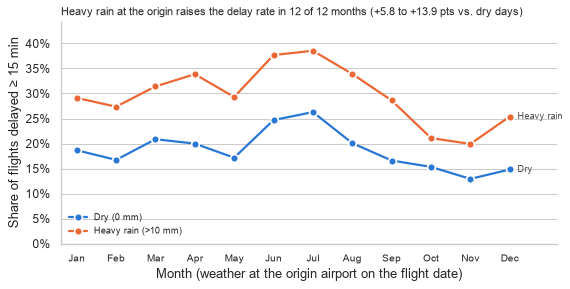

heavy-rain minus dry-day delay rate (pts): {1: 10.5, 2: 10.6, 3: 10.5, 4: 13.9, 5: 12.1, 6: 13.0, 7: 12.2, 8: 13.8, 9: 12.0, 10: 5.8, 11: 7.0, 12: 10.6}


In [61]:
RAIN_BINS, RAIN_LABELS = [-np.inf, 0, 10, np.inf], ["Dry (0 mm)", "Light rain (≤10 mm)", "Heavy rain (>10 mm)"]
rain = pd.cut(tgt["wx_dep_prcp"], RAIN_BINS, labels=RAIN_LABELS)
by_month = tgt.groupby([tgt["month"], rain], observed=False)["delayed_flight"].agg(rate="mean", n="size").unstack()
assert (by_month["n"] >= MIN_FLIGHTS).all().all()

dry, wet = by_month[("rate", RAIN_LABELS[0])], by_month[("rate", RAIN_LABELS[2])]
gap = (wet - dry) * 100
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(12)
for label, r, color in [(RAIN_LABELS[0], dry, "#2a78d6"), (RAIN_LABELS[2], wet, "#eb6834")]:
    ax.plot(x, r.to_numpy(), color=color, lw=2, marker="o", ms=7, mec="white", mew=1.5, label=label, zorder=3)
    ax.annotate(label.split(" (")[0], (x[-1], r.iloc[-1]), xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=8, color="#52514e")
ax.set_xticks(x, MONTHS, fontsize=9)
ax.set_xlim(-0.4, 12.2)
ax.set_ylim(0, max(dry.max(), wet.max()) * 1.15)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_ylabel("Share of flights delayed ≥ 15 min")
ax.set_xlabel("Month (weather at the origin airport on the flight date)")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", fontsize=8, frameon=False)
ax.set_title(f"Heavy rain at the origin raises the delay rate in {(gap > 0).sum()} of 12 months "
             f"(+{gap.min():.1f} to +{gap.max():.1f} pts vs. dry days)" if (gap > 0).all() else
             f"Heavy rain vs. dry days at the origin: gap ranges {gap.min():+.1f} to {gap.max():+.1f} pts by month",
             fontsize=10, loc="left")
sns.despine(ax=ax)
plt.show()
print("heavy-rain minus dry-day delay rate (pts):", gap.round(1).to_dict())

## Stage 6: Models for `delayed_flight` (departure delay ≥ 15 min)

- **Prediction time: the evening before departure.** Allowed features are the schedule (airline, airports, daypart, weekday, distance, days to the nearest holiday), the assigned aircraft, and the flight day's weather.
- **Weather is an optimistic upper bound.** The `wx_*` columns are the *observed* daily values, used as a stand-in for a perfect forecast. LightGBM is also trained without weather to measure how much weather adds.
- **Split by time:** train Jan–Aug, validate Sep–Oct (feature selection, early stopping), test Nov–Dec (scored once). `month` is not a feature, because the test months never appear in training.
- **Single split:** the base rate drifts by month (Jul 28.8% vs Nov 13.9%), so the splits have different base rates. The base rate is reported next to every metric. Walk-forward folds are the next step for a robust estimate.
- **Models:**
  1. a lookup baseline (historical rate per origin × daypart)
  2. a logistic regression with forward feature selection
  3. LightGBM (binary objective) with and without weather

In [62]:
import time, warnings
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss, brier_score_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder
import lightgbm as lgb

SEED, TARGET = 42, "delayed_flight"
# Only known after departure, or the target itself -> never a feature
POST_DEPARTURE_COLS = ["Dep_Delay", "Dep_Delay_Tag", "Dep_Delay_Type", "Arr_Delay", "Arr_Delay_Type", "Flight_Duration",
                       "Delay_Carrier", "Delay_Weather", "Delay_NAS", "Delay_Security", "Delay_LastAircraft",
                       "Cancelled", "Diverted", TARGET]

# Snowfall proxy: day-over-day increase in snow depth at the airport (NaN on Jan 1)
wx_sorted = weather.assign(FlightDate=pd.to_datetime(weather["time"])).sort_values(["airport_id", "FlightDate"])
assert (wx_sorted.groupby("airport_id").size() == 365).all()  # consecutive days, so diff() = previous day
wx_sorted["snow_new"] = wx_sorted.groupby("airport_id")["snow"].diff().clip(lower=0)
for side, col in [("dep", "Dep_Airport"), ("arr", "Arr_Airport")]:
    w = wx_sorted[["airport_id", "FlightDate", "snow_new"]].rename(columns={"airport_id": col, "snow_new": f"wx_{side}_snow_new"})
    w = w[w[col].isin(tgt[col].cat.categories)]  # weather has 14 airports with no flights
    w[col] = w[col].astype(tgt[col].dtype)
    tgt, _ = checked_merge(tgt, w, on=[col, "FlightDate"], name=f"+ snow_new ({side})")

# Brute-force check of snow_new on a sample
rng = np.random.default_rng(SEED)
for i in rng.choice(len(tgt), 200, replace=False):
    r = tgt.iloc[i]
    a = weather[weather["airport_id"] == r["Dep_Airport"]].set_index("time")["snow"]
    d = r["FlightDate"]
    prev = a.get((d - pd.Timedelta(days=1)).strftime("%Y-%m-%d"))
    exp = np.nan if prev is None else max(0.0, a[d.strftime("%Y-%m-%d")] - prev)
    assert (np.isnan(exp) and np.isnan(r["wx_dep_snow_new"])) or np.isclose(exp, r["wx_dep_snow_new"])

# Days to the nearest US federal holiday (capped at 30)
hol = USFederalHolidayCalendar().holidays("2022-11-01", "2024-02-28").to_numpy()
dates = tgt["FlightDate"].drop_duplicates().to_numpy()
dist = np.abs((dates[:, None] - hol[None, :]) / np.timedelta64(1, "D")).min(axis=1)
tgt["sched_days_to_holiday"] = tgt["FlightDate"].map(pd.Series(np.minimum(dist, 30), index=dates))

WX_FEATS = [("prcp", "wx_precip"), ("snow", "wx_snow"), ("snow_new", "wx_snow"), ("wspd", "wx_wind"),
            ("tavg", "wx_temp"), ("pres", "wx_pressure")]
FEATURES = pd.DataFrame([
    ("Airline", "airline", "cat", "schedule"),
    ("Dep_Airport", "dep_airport", "cat", "schedule"),
    ("Arr_Airport", "arr_airport", "cat", "schedule"),
    ("DepTime_label", "dep_time", "cat", "schedule (assumed scheduled time)"),
    ("Day_Of_Week", "day_of_week", "cat", "schedule"),
    ("Distance_type", "distance", "cat", "schedule"),
    ("sched_days_to_holiday", "holiday", "num", "schedule"),
    ("Manufacturer", "aircraft_type", "cat", "day_before (tail assignment)"),
    ("Model", "aircraft_type", "cat", "day_before (tail assignment)"),
    ("Aicraft_age", "aircraft_age", "num", "day_before (tail assignment)"),
    *[(f"wx_{s}_{v}", g, "num", "day_end (perfect-forecast proxy)") for v, g in WX_FEATS for s in ("dep", "arr")],
], columns=["feature", "group", "kind", "available_at"])
assert not set(FEATURES["feature"]) & set(POST_DEPARTURE_COLS)
assert FEATURES["feature"].is_unique
ALL_FEATS = FEATURES["feature"].tolist()
NO_WX_FEATS = FEATURES.loc[~FEATURES["group"].str.startswith("wx_"), "feature"].tolist()
KIND = FEATURES.set_index("feature")["kind"].to_dict()
GROUPS = FEATURES.groupby("group", sort=False)["feature"].apply(list).to_dict()

m = tgt["FlightDate"].dt.month
tgt["split"] = np.select([m <= 8, m <= 10], ["train", "val"], "test")
model_df = tgt[["FlightDate", "split", TARGET, *ALL_FEATS]]
train, val, test = (model_df[model_df["split"] == s] for s in ("train", "val", "test"))
FEATURES

+ snow_new (dep): 6,759,956 -> 6,759,956 rows | unmatched: 0
+ snow_new (arr): 6,759,956 -> 6,759,956 rows | unmatched: 0


,feature,group,kind,available_at
0,Airline,airline,cat,schedule
1,Dep_Airport,dep_airport,cat,schedule
2,Arr_Airport,arr_airport,cat,schedule
3,DepTime_label,dep_time,cat,schedule (assumed scheduled time)
4,Day_Of_Week,day_of_week,cat,schedule
5,Distance_type,distance,cat,schedule
6,sched_days_to_holiday,holiday,num,schedule
7,Manufacturer,aircraft_type,cat,day_before (tail assignment)
8,Model,aircraft_type,cat,day_before (tail assignment)
9,Aicraft_age,aircraft_age,num,day_before (tail assignment)


In [63]:
# Drift check: base rate per split and categories unseen in training
drift = pd.DataFrame({
    s: {"rows": len(d), "base_rate_%": round(d[TARGET].mean() * 100, 1),
        **{f"unseen_{c}_%": round(100 * (~d[c].isin(set(train[c]))).mean(), 2) for c in ["Dep_Airport", "Arr_Airport", "Model"]}}
    for s, d in [("train", train), ("val", val), ("test", test)]
}).T
drift

,rows,base_rate_%,unseen_Dep_Airport_%,unseen_Arr_Airport_%,unseen_Model_%
train,4469806.0,22.7,0.0,0.0,0.0
val,1159108.0,17.2,0.0,0.0,0.0
test,1131042.0,15.2,0.0,0.0,0.0


In [64]:
def scores(y, p):
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p), "log_loss": log_loss(y, p),
            "brier": brier_score_loss(y, p), "mean_pred": p.mean(), "base_rate": y.mean()}

preds = {}  # model -> {"val": p, "test": p}

# Baseline 1: historical delay rate per (origin, daypart) from training, smoothed toward the prior
keys, M_SMOOTH = ["Dep_Airport", "DepTime_label"], 50
prior = train[TARGET].mean()
rate = train.groupby(keys, observed=True)[TARGET].agg(s="sum", n="count")
rate["p"] = (rate["s"] + prior * M_SMOOTH) / (rate["n"] + M_SMOOTH)
preds["lookup (origin × daypart)"] = {
    s: d[keys].merge(rate["p"].reset_index(), on=keys, how="left", validate="many_to_one")["p"].fillna(prior).to_numpy()
    for s, d in [("val", val), ("test", test)]
}
scores(val[TARGET], preds["lookup (origin × daypart)"]["val"])

{'pr_auc': 0.2575935775616295,
 'roc_auc': 0.6386657221683143,
 'log_loss': 0.4513253468494613,
 'brier': 0.14094343881377522,
 'mean_pred': np.float64(0.22650255473348208),
 'base_rate': np.float64(0.17168201755142748)}

### Logistic regression with forward feature selection
- **Encoding:** categoricals are one-hot encoded; levels with fewer than 200 rows are pooled. Numerics are median-imputed and cut into up to 10 quantile bins, so the model can capture non-linear shapes like the U-shaped temperature effect.
- **Selection:** greedy forward selection over **feature groups** (e.g. all precipitation columns together). At each step it adds the group that raises **validation PR-AUC** the most, and it stops when the gain drops below 0.002.
- **Data:** selection runs on a 200k-row sample of train and val to keep it fast. The final model is refit on the full training set using only the selected groups.

In [65]:
def make_logreg(feats):
    cats = [f for f in feats if KIND[f] == "cat"]
    nums = [f for f in feats if KIND[f] == "num"]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200), cats),
        ("num", make_pipeline(SimpleImputer(strategy="median"),
                              KBinsDiscretizer(n_bins=10, strategy="quantile", encode="onehot", random_state=SEED)), nums),
    ], sparse_threshold=1.0)
    return make_pipeline(pre, LogisticRegression(C=1.0, max_iter=1000))

def feats_of(groups, group_map):
    return [f for g in groups for f in group_map[g]]

def forward_select(group_map, tr, va, min_gain=0.002, n=200_000):
    """Greedy forward selection over feature groups, scored by validation PR-AUC on row samples."""
    s_tr, s_va = tr.sample(n, random_state=SEED), va.sample(n, random_state=SEED)
    selected, path, best = [], [], 0.0
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)  # KBinsDiscretizer: duplicate quantile edges (e.g. many 0 mm days) get merged
        while len(selected) < len(group_map):
            cand = {}
            for g in group_map:
                if g in selected:
                    continue
                f = feats_of(selected + [g], group_map)
                mdl = make_logreg(f).fit(s_tr[f], s_tr[TARGET])
                cand[g] = average_precision_score(s_va[TARGET], mdl.predict_proba(s_va[f])[:, 1])
            g, s = max(cand.items(), key=lambda kv: kv[1])
            kept = s - best >= min_gain
            path.append({"step": len(selected) + 1, "group": g, "val_pr_auc": s, "gain": s - best, "kept": kept})
            if not kept:
                break
            selected.append(g)
            best = s
    return selected, pd.DataFrame(path)

t0 = time.time()
selected, path = forward_select(GROUPS, train, val)
print(f"forward selection: {time.time() - t0:.0f}s | kept {len(selected)} of {len(GROUPS)} groups: {selected}")
print("dropped:", [g for g in GROUPS if g not in selected])
path.round(4)

forward selection: 56s | kept 6 of 14 groups: ['airline', 'dep_time', 'wx_precip', 'dep_airport', 'day_of_week', 'wx_temp']
dropped: ['arr_airport', 'distance', 'holiday', 'aircraft_type', 'aircraft_age', 'wx_snow', 'wx_wind', 'wx_pressure']


,step,group,val_pr_auc,gain,kept
0,1,airline,0.2215,0.2215,True
1,2,dep_time,0.2714,0.0499,True
2,3,wx_precip,0.2865,0.0152,True
3,4,dep_airport,0.2938,0.0072,True
4,5,day_of_week,0.2984,0.0046,True
5,6,wx_temp,0.3019,0.0036,True
6,7,arr_airport,0.3034,0.0014,False


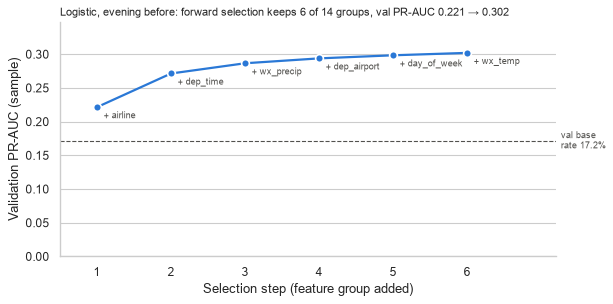

In [66]:
def plot_selection(path, n_groups, va, label):
    kept = path[path["kept"]]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(kept["step"], kept["val_pr_auc"], color="#2a78d6", lw=2, marker="o", ms=7, mec="white", mew=1.5, zorder=3)
    for _, r in kept.iterrows():
        ax.annotate(f"+ {r['group']}", (r["step"], r["val_pr_auc"]), xytext=(6, -10), textcoords="offset points",
                    fontsize=8, color="#52514e")
    ax.axhline(va[TARGET].mean(), color="#52514e", ls="--", lw=1)
    ax.text(1.01, va[TARGET].mean(), f"val base\nrate {va[TARGET].mean():.1%}", transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=8, color="#52514e")
    ax.set_xticks(kept["step"])
    ax.set_xlim(0.5, kept["step"].max() + 1.2)
    ax.set_ylim(0, kept["val_pr_auc"].max() * 1.15)
    ax.set_xlabel("Selection step (feature group added)")
    ax.set_ylabel("Validation PR-AUC (sample)")
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{label}: forward selection keeps {len(kept)} of {n_groups} groups, val PR-AUC "
                 f"{kept['val_pr_auc'].iloc[0]:.3f} → {kept['val_pr_auc'].iloc[-1]:.3f}", fontsize=10, loc="left")
    sns.despine(ax=ax)
    plt.show()

plot_selection(path, len(GROUPS), val, "Logistic, evening before")

In [67]:
# Final logistic regression: selected groups, full training set
LOGREG_FEATS = feats_of(selected, GROUPS)
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    logreg = make_logreg(LOGREG_FEATS).fit(train[LOGREG_FEATS], train[TARGET])
preds["logistic (selected)"] = {s: logreg.predict_proba(d[LOGREG_FEATS])[:, 1] for s, d in [("val", val), ("test", test)]}
print(f"logistic fit on {len(train):,} rows in {time.time() - t0:.0f}s")
scores(val[TARGET], preds["logistic (selected)"]["val"])

logistic fit on 4,469,806 rows in 31s


{'pr_auc': 0.305582033692289,
 'roc_auc': 0.6712908678342406,
 'log_loss': 0.4416966181814426,
 'brier': 0.1375592056478445,
 'mean_pred': np.float64(0.22509856604430029),
 'base_rate': np.float64(0.17168201755142748)}

### LightGBM (binary)
Categoricals are passed as pandas `category` columns and handled natively by LightGBM. Early stopping uses the validation set's PR-AUC. The same parameters are trained twice, with and without the weather features.

In [68]:
LGB_PARAMS = dict(objective="binary", metric="average_precision", learning_rate=0.03, num_leaves=63,
                  min_child_samples=2000, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l2=50.0, cat_smooth=100, cat_l2=50.0, min_data_per_group=1000, max_cat_threshold=32,
                  seed=SEED, n_jobs=-1, verbose=-1)

def fit_lgbm(feats, tr, va):
    dtr = lgb.Dataset(tr[feats], tr[TARGET])
    dva = lgb.Dataset(va[feats], va[TARGET], reference=dtr)
    return lgb.train(LGB_PARAMS, dtr, num_boost_round=3000, valid_sets=[dva],
                     callbacks=[lgb.early_stopping(100, verbose=False)])

lgbms = {}
for name, feats in [("lightgbm (all features)", ALL_FEATS), ("lightgbm (no weather)", NO_WX_FEATS)]:
    t0 = time.time()
    lgbms[name] = mdl = fit_lgbm(feats, train, val)
    preds[name] = {s: mdl.predict(d[feats], num_iteration=mdl.best_iteration) for s, d in [("val", val), ("test", test)]}
    print(f"{name}: best iteration {mdl.best_iteration} | {time.time() - t0:.0f}s")

lightgbm (all features): best iteration 699 | 205s
lightgbm (no weather): best iteration 232 | 74s


In [69]:
# Comparison: validation and test (test scored once, here). Saved together with the T-60 models below.
rows = [{"model": name, "split": s, **scores(d[TARGET].to_numpy(), p[s])}
        for name, p in preds.items() for s, d in [("val", val), ("test", test)]]
metrics = pd.DataFrame(rows)
metrics.pivot(index="model", columns="split", values=["pr_auc", "roc_auc", "mean_pred", "base_rate"]).round(3)

pr_auc        roc_auc        mean_pred         \
split                       test    val    test    val      test    val   
model                                                                     
lightgbm (all features)    0.276  0.325   0.670  0.689     0.185  0.207   
lightgbm (no weather)      0.262  0.303   0.656  0.675     0.227  0.216   
logistic (selected)        0.262  0.306   0.653  0.671     0.197  0.225   
lookup (origin × daypart)  0.225  0.258   0.621  0.639     0.228  0.227   

                          base_rate         
split                          test    val  
model                                       
lightgbm (all features)       0.152  0.172  
lightgbm (no weather)         0.152  0.172  
logistic (selected)           0.152  0.172  
lookup (origin × daypart)     0.152  0.172

In [70]:
# Test PR-AUC per month (Nov vs Dec), next to each month's base rate
tm = test["FlightDate"].dt.month.to_numpy()
by_month = pd.DataFrame({name: {MONTHS[mo - 1]: average_precision_score(test[TARGET].to_numpy()[tm == mo], p["test"][tm == mo])
                                for mo in (11, 12)} for name, p in preds.items()}).T.round(3)
by_month.columns = [f"pr_auc_{c}" for c in by_month.columns]
for mo in (11, 12):
    by_month[f"base_rate_{MONTHS[mo - 1]}"] = round(test.loc[tm == mo, TARGET].mean(), 3)
by_month

,pr_auc_Nov,pr_auc_Dec,base_rate_Nov,base_rate_Dec
lookup (origin × daypart),0.204,0.245,0.139,0.166
logistic (selected),0.240,0.281,0.139,0.166
lightgbm (all features),0.252,0.302,0.139,0.166
lightgbm (no weather),0.243,0.289,0.139,0.166


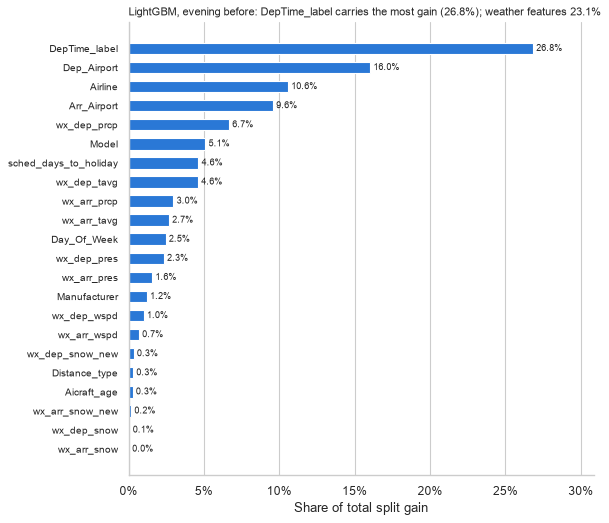

In [71]:
# LightGBM feature importance (gain, share of total)
def plot_importance(mdl, label):
    imp = (pd.Series(mdl.feature_importance("gain"), index=mdl.feature_name())
           .pipe(lambda s: s / s.sum()).sort_values())
    shares = {"weather": imp[imp.index.str.startswith("wx_")].sum(), "previous-leg/ops": imp[imp.index.str.startswith("ops_")].sum()}
    fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(imp) + 1.2))
    y = np.arange(len(imp))
    bars = ax.barh(y, imp.to_numpy(), height=0.6, color="#2a78d6", zorder=2)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in imp], padding=3, fontsize=8)
    ax.set_yticks(y, imp.index, fontsize=9)
    ax.set_xlim(0, imp.max() * 1.15)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.set_xlabel("Share of total split gain")
    ax.grid(axis="y", visible=False)
    extra = "; ".join(f"{k} features {v:.1%}" for k, v in shares.items() if v > 0)
    ax.set_title(f"{label}: {imp.index[-1]} carries the most gain ({imp.iloc[-1]:.1%}); {extra}", fontsize=10, loc="left")
    sns.despine(ax=ax)
    plt.show()
    return imp

imp_evening = plot_importance(lgbms["lightgbm (all features)"], "LightGBM, evening before")

## Stage 7: Predicting 1 hour before departure (T−60)

**Prediction time: 60 minutes before the flight's scheduled departure.** On top of the evening-before features, we now know what happened to the **previous flight of the same aircraft** that day.

**Rebuilding each aircraft's day (grouped by `Tail_Number` + `FlightDate`).** The data has no departure times, so the order within a day is reconstructed:
1. **Daypart first:** Morning → Afternoon → Evening.
2. **Then the route chain:** within a daypart, the next leg departs from the airport where the previous one arrived.
3. **Night legs** go first if they chain into the day's first leg (early-morning departure), otherwise last.

This includes cancelled and diverted legs, because they are part of the aircraft's day.

**What is known at T−60 (conservative):**
- **Assume a tight connection:** the previous leg was scheduled to depart at T − (its scheduled block time) − `TURN_MIN`. The block time is approximated by the route's median actual duration, taken from **training months only**. `TURN_MIN` = 25 min is a short turn on purpose: a shorter turn means less is known at T−60.
- **If the previous leg had departed by T−60**, its departure delay is known exactly.
- **If it hadn't**, we only know it is late by at least the cap, so the value is censored at the cap and `ops_prev_dep_censored = 1`.
- **Not used:** the previous leg's **arrival delay**, because it often lands less than 60 minutes before our departure.
- **Weather is still the daily observed value** (the perfect-forecast proxy).

In [72]:
RANK = {"Morning": 1, "Afternoon": 2, "Evening": 3, "Night": 9}
TURN_MIN = 25  # assumed minimum scheduled turnaround (shorter -> less known at T-60 -> conservative)

def order_legs(dep, arr, rank):
    """Order one aircraft-day's legs: daypart first, then the route chain (dep == previous arr).
    Night legs go first if they chain into the first day leg, else last."""
    n = len(dep)
    if n == 1:
        return [0]
    seq_, loc = [], None
    for r in (1, 2, 3):
        pool = [i for i in range(n) if rank[i] == r]
        while pool:
            pick = next((i for i in pool if dep[i] == loc), None)
            if pick is None:  # start of a chain: a leg not departing from where another pool leg arrives
                arrs = {arr[j] for j in pool}
                pick = next((i for i in pool if dep[i] not in arrs), pool[0])
            seq_.append(pick)
            pool.remove(pick)
            loc = arr[pick]
    for i in (i for i in range(n) if rank[i] == 9):
        if seq_ and arr[i] == dep[seq_[0]] and dep[i] != arr[seq_[-1]]:
            seq_.insert(0, i)
        else:
            seq_.append(i)
    return seq_

# All legs (incl. cancelled/diverted), one block per aircraft-day
seq = df[["flight_id", "Tail_Number", "FlightDate", "Dep_Airport", "Arr_Airport", "DepTime_label", "Distance_type",
          "Dep_Delay", "Flight_Duration", "Cancelled", "Diverted"]].sort_values(["Tail_Number", "FlightDate", "flight_id"])
seq["day_id"] = seq.groupby(["Tail_Number", "FlightDate"], observed=True, sort=False).ngroup()
assert seq["day_id"].is_monotonic_increasing

t0 = time.time()
d = seq["day_id"].to_numpy()
starts = np.flatnonzero(np.r_[True, d[1:] != d[:-1]])
ends = np.r_[starts[1:], len(seq)]
dep, arr = seq["Dep_Airport"].astype(str).to_numpy(), seq["Arr_Airport"].astype(str).to_numpy()
rank = seq["DepTime_label"].astype(str).map(RANK).to_numpy()
leg_no = np.empty(len(seq), dtype=np.int16)
for s, e in zip(starts, ends):
    leg_no[s + np.asarray(order_legs(dep[s:e], arr[s:e], rank[s:e]))] = np.arange(1, e - s + 1)
seq["ops_leg_no"] = leg_no
seq = seq.sort_values(["day_id", "ops_leg_no"]).reset_index(drop=True)
seq["ops_legs_in_day"] = seq.groupby("day_id")["ops_leg_no"].transform("max")
print(f"sequenced {len(starts):,} aircraft-days in {time.time() - t0:.0f}s")

# Route duration (scheduled-block proxy) from training months only
in_train = seq["FlightDate"].dt.month <= 8
route_med = (seq[in_train].groupby(["Dep_Airport", "Arr_Airport"], observed=True)["Flight_Duration"]
             .median().rename("route_med_dur").reset_index())
dist_med = seq[in_train].groupby("Distance_type", observed=True)["Flight_Duration"].median()
seq, n_new_route = checked_merge(seq, route_med, on=["Dep_Airport", "Arr_Airport"], name="+ route median duration")
seq["route_med_dur"] = seq["route_med_dur"].fillna(seq["Distance_type"].astype(str).map(dist_med.rename(index=str)))
assert seq["route_med_dur"].notna().all()

# Previous-leg features (rows are in sequence order within each aircraft-day)
has_prev = seq["day_id"].eq(seq["day_id"].shift())
prev = lambda c: seq[c].shift().where(has_prev)
prev_delay, prev_cap = prev("Dep_Delay"), prev("route_med_dur") + TURN_MIN - 60
seq["ops_prev_dep_delay_known"] = np.minimum(prev_delay, prev_cap)
seq["ops_prev_dep_censored"] = prev_delay.gt(prev_cap).astype(float).where(prev_delay.notna())
seq["ops_prev_cancelled"] = prev("Cancelled")
seq["ops_prev_diverted"] = prev("Diverted")
seq["ops_prev_chain_ok"] = seq["Dep_Airport"].astype(str).eq(seq["Arr_Airport"].astype(str).shift()).astype(float).where(has_prev)

# Checks: daypart order respected, and a brute-force recomputation of the previous-leg features
r_ = seq["DepTime_label"].astype(str).map(RANK)
both_day = has_prev & r_.ne(9) & r_.shift().ne(9)
assert (r_[both_day] >= r_.shift()[both_day]).all()
rng = np.random.default_rng(SEED)
for i in rng.choice(np.flatnonzero(has_prev), 200, replace=False):
    r = seq.iloc[i]
    day = seq[(seq["Tail_Number"] == r["Tail_Number"]) & (seq["FlightDate"] == r["FlightDate"])]
    pl = day[day["ops_leg_no"] == r["ops_leg_no"] - 1].iloc[0]
    exp = min(pl["Dep_Delay"], pl["route_med_dur"] + TURN_MIN - 60) if pd.notna(pl["Dep_Delay"]) else np.nan
    got = r["ops_prev_dep_delay_known"]
    assert (np.isnan(exp) and np.isnan(got)) or np.isclose(exp, got)
    assert r["ops_prev_cancelled"] == pl["Cancelled"]

chain_ok = seq.loc[has_prev, "ops_prev_chain_ok"].mean()
night_multi = seq["DepTime_label"].eq("Night") & seq["ops_legs_in_day"].gt(1)
night_first = (night_multi & seq["ops_leg_no"].eq(1)).sum() / night_multi.sum()
print(f"legs with a previous leg that day: {has_prev.mean():.1%} | route chain consistent: {chain_ok:.1%} | "
      f"night legs placed first: {night_first:.1%} | previous leg censored at T-60: {seq['ops_prev_dep_censored'].mean():.1%}")
findings += [
    ("flights (sequencing)", "Within-day leg order reconstructed (no departure times); previous leg's arrival airport != this departure airport",
     int((has_prev & seq["ops_prev_chain_ok"].eq(0)).sum()), "Kept; flagged with ops_prev_chain_ok = 0"),
    ("flights (sequencing)", f"Night legs placed before the day's first leg ({night_first:.0%} of Night legs in multi-leg days)",
     int(night_multi.sum()), "Night appears to be mostly early-morning departures"),
]

OPS_FEATS = ["ops_leg_no", "ops_legs_in_day", "ops_prev_dep_delay_known", "ops_prev_dep_censored",
             "ops_prev_cancelled", "ops_prev_diverted", "ops_prev_chain_ok"]
tgt, _ = checked_merge(tgt, seq[["flight_id", *OPS_FEATS]], on="flight_id", validate="one_to_one", name="+ ops features")

sequenced 1,665,007 aircraft-days in 23s
+ route median duration: 6,847,892 -> 6,847,892 rows | unmatched: 5,167
legs with a previous leg that day: 75.7% | route chain consistent: 95.0% | night legs placed first: 81.9% | previous leg censored at T-60: 4.7%
+ ops features: 6,759,956 -> 6,759,956 rows | unmatched: 0


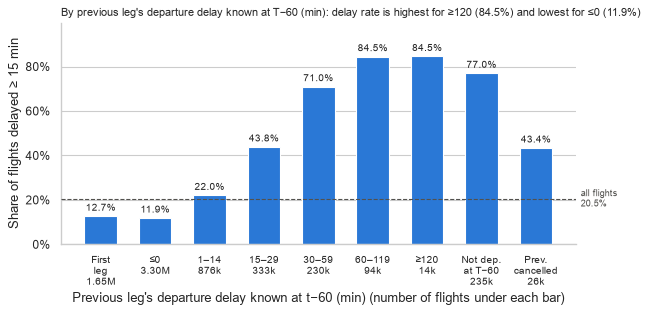

In [73]:
# Delay rate by what we know about the previous leg at T-60
state = pd.cut(tgt["ops_prev_dep_delay_known"], [-np.inf, 0, 14, 29, 59, 119, np.inf],
               labels=["≤0", "1–14", "15–29", "30–59", "60–119", "≥120"]).astype(str)
state[tgt["ops_prev_dep_censored"].eq(1)] = "not departed"
state[tgt["ops_prev_cancelled"].eq(1)] = "cancelled"
state[tgt["ops_leg_no"].eq(1)] = "first leg"
tgt["prev_state"] = state
PREV_ORDER = ["first leg", "≤0", "1–14", "15–29", "30–59", "60–119", "≥120", "not departed", "cancelled"]
PREV_LABELS = ["First\nleg", "≤0", "1–14", "15–29", "30–59", "60–119", "≥120", "Not dep.\nat T−60", "Prev.\ncancelled"]
assert set(tgt["prev_state"].unique()) <= set(PREV_ORDER)
prev_rates = plot_delay_rate("prev_state", "previous leg's departure delay known at T−60 (min)", PREV_ORDER, PREV_LABELS)

forward selection (T-60): 65s | kept 6 of 17 groups: ['ops_prev_delay', 'airline', 'dep_time', 'wx_precip', 'ops_leg', 'day_of_week']
dropped: ['dep_airport', 'arr_airport', 'distance', 'holiday', 'aircraft_type', 'aircraft_age', 'wx_snow', 'wx_wind', 'wx_temp', 'wx_pressure', 'ops_prev_status']


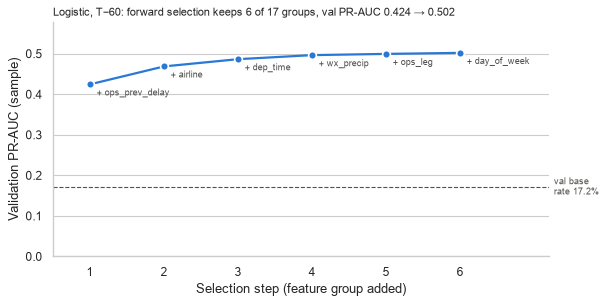

,step,group,val_pr_auc,gain,kept
0,1,ops_prev_delay,0.4244,0.4244,True
1,2,airline,0.4686,0.0442,True
2,3,dep_time,0.4864,0.0178,True
3,4,wx_precip,0.4964,0.0100,True
4,5,ops_leg,0.4994,0.0031,True
5,6,day_of_week,0.5019,0.0025,True
6,7,wx_temp,0.5033,0.0014,False


In [74]:
OPS_SPEC = pd.DataFrame([
    ("ops_leg_no", "ops_leg", "num", "schedule (reconstructed order)"),
    ("ops_legs_in_day", "ops_leg", "num", "schedule (reconstructed order)"),
    ("ops_prev_dep_delay_known", "ops_prev_delay", "num", "T-60 (censored if previous leg not departed yet)"),
    ("ops_prev_dep_censored", "ops_prev_delay", "num", "T-60"),
    ("ops_prev_cancelled", "ops_prev_status", "num", "T-60"),
    ("ops_prev_diverted", "ops_prev_status", "num", "T-60"),
    ("ops_prev_chain_ok", "ops_prev_status", "num", "schedule (reconstructed order)"),
], columns=FEATURES.columns)
FEATURES_T60 = pd.concat([FEATURES, OPS_SPEC], ignore_index=True)
assert not set(FEATURES_T60["feature"]) & set(POST_DEPARTURE_COLS)
KIND.update(OPS_SPEC.set_index("feature")["kind"])
GROUPS_T60 = FEATURES_T60.groupby("group", sort=False)["feature"].apply(list).to_dict()
T60_FEATS = FEATURES_T60["feature"].tolist()

model_df = tgt[["FlightDate", "split", TARGET, "prev_state", "DepTime_label", *[f for f in T60_FEATS if f != "DepTime_label"]]]
train, val, test = (model_df[model_df["split"] == s] for s in ("train", "val", "test"))
preds_t60 = {}

# Baseline: historical delay rate per (previous-leg state, daypart), smoothed toward the prior
keys = ["prev_state", "DepTime_label"]
prior = train[TARGET].mean()
rate = train.groupby(keys, observed=True)[TARGET].agg(s="sum", n="count")
rate["p"] = (rate["s"] + prior * M_SMOOTH) / (rate["n"] + M_SMOOTH)
preds_t60["lookup (prev leg × daypart)"] = {
    s: d[keys].merge(rate["p"].reset_index(), on=keys, how="left", validate="many_to_one")["p"].fillna(prior).to_numpy()
    for s, d in [("val", val), ("test", test)]
}

t0 = time.time()
selected_t60, path_t60 = forward_select(GROUPS_T60, train, val)
print(f"forward selection (T-60): {time.time() - t0:.0f}s | kept {len(selected_t60)} of {len(GROUPS_T60)} groups: {selected_t60}")
print("dropped:", [g for g in GROUPS_T60 if g not in selected_t60])
plot_selection(path_t60, len(GROUPS_T60), val, "Logistic, T−60")
path_t60.round(4)

In [75]:
LOGREG_T60_FEATS = feats_of(selected_t60, GROUPS_T60)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    logreg_t60 = make_logreg(LOGREG_T60_FEATS).fit(train[LOGREG_T60_FEATS], train[TARGET])
preds_t60["logistic (selected)"] = {s: logreg_t60.predict_proba(d[LOGREG_T60_FEATS])[:, 1] for s, d in [("val", val), ("test", test)]}

t0 = time.time()
lgb_t60 = fit_lgbm(T60_FEATS, train, val)
preds_t60["lightgbm (all features)"] = {s: lgb_t60.predict(d[T60_FEATS], num_iteration=lgb_t60.best_iteration)
                                        for s, d in [("val", val), ("test", test)]}
print(f"lightgbm T-60: best iteration {lgb_t60.best_iteration} | {time.time() - t0:.0f}s")

lightgbm T-60: best iteration 1419 | 336s


In [76]:
# Both prediction times side by side (same rows, same split); saved to outputs/
metrics_t60 = pd.DataFrame([{"model": name, "split": s, **scores(d[TARGET].to_numpy(), p[s])}
                            for name, p in preds_t60.items() for s, d in [("val", val), ("test", test)]])
all_metrics = pd.concat([metrics.assign(prediction_time="evening before"), metrics_t60.assign(prediction_time="T-60 min")],
                        ignore_index=True)
all_metrics.to_csv("outputs/flights2023_delay_model_metrics.csv", index=False)
(all_metrics.pivot(index=["prediction_time", "model"], columns="split", values=["pr_auc", "roc_auc", "mean_pred", "base_rate"])
 .round(3))

pr_auc        roc_auc         \
split                                         test    val    test    val   
prediction_time model                                                      
T-60 min        lightgbm (all features)      0.541  0.577   0.784  0.794   
                logistic (selected)          0.471  0.504   0.753  0.763   
                lookup (prev leg × daypart)  0.444  0.476   0.728  0.739   
evening before  lightgbm (all features)      0.276  0.325   0.670  0.689   
                lightgbm (no weather)        0.262  0.303   0.656  0.675   
                logistic (selected)          0.262  0.306   0.653  0.671   
                lookup (origin × daypart)    0.225  0.258   0.621  0.639   

                                            mean_pred        base_rate         
split                                            test    val      test    val  
prediction_time model                                                          
T-60 min        lightgbm (all features)         0.172  0.195     0.152  0.172  
                logistic (selected)             0.202  0.205     0.152  0.172  
                lookup (prev leg × daypart)     0.200  0.206     0.152  0.172  
evening before  lightgbm (all features)         0.185  0.207     0.152  0.172  
                lightgbm (no weather)           0.227  0.216     0.152  0.172  
                logistic (selected)             0.197  0.225     0.152  0.172  
                lookup (origin × daypart)       0.228  0.227     0.152  0.172

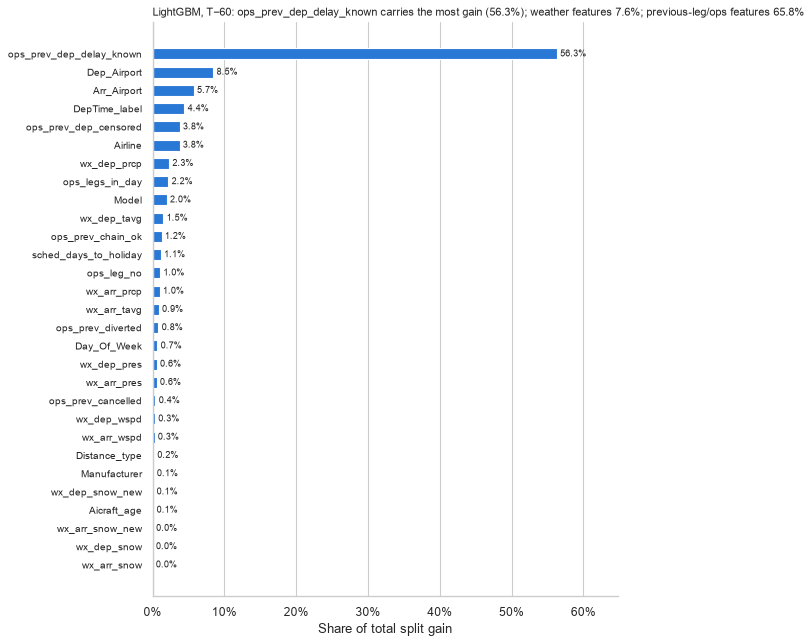

In [77]:
imp_t60 = plot_importance(lgb_t60, "LightGBM, T−60")

In [78]:
findings_df = pd.DataFrame(findings, columns=["table", "issue", "rows", "decision"])
findings_df

,table,issue,rows,decision
0,flights,Identical full rows (no flight number to tell ...,31,Kept: could be distinct flights by the same ta...
1,cancelled_diverted,Identical full rows (no flight number to tell ...,945,Kept: could be distinct flights by the same ta...
2,flights+cancelled_diverted,Loose key appears in both tables,747,Kept: the loose key isn't unique even within f...
3,cancelled_diverted,Arr_Delay/Flight_Duration/delay causes 0-fille...,104488,Set to NaN
4,cancelled_diverted,Dep_Delay on cancelled flights (0-filled; a fe...,87936,"Set to NaN (3,323 had a nonzero value)"
5,cancelled_diverted,Tail_Number never seen in flights -> no aircra...,15487,Kept with NaN
6,both,Label sets differ between tables; '<5min' and ...,6847892,Delay bands recomputed from minutes (<=15/16-6...
7,weather,tmin <= tavg <= tmax violated,358,Kept; only tavg is used in the plots
8,weather,"tmin below -45 °C (min -76 °C, implausible for...",1,Kept; flag before using tmin as a feature
9,flights (sequencing),Within-day leg order reconstructed (no departu...,259008,Kept; flagged with ops_prev_chain_ok = 0
